# Лабораторная работа № 1
**Выполнил:** Чаннов Павел  
**Группа:** 24-ИИ \
**Вариант:** 4

---

## 1. Постановка задачи
**Цель работы:** Получение навыков предобработки данных и построения моделей глубоких полносвязных нейронных сетей (библиотека Keras) для решения задачи регрессии.

**Описание задачи:** Компания TFI владеет крупными сетями ресторанов. Открытие новых точек сопряжено с большими финансовыми рисками (неудачные рестораны закрываются в течение 18 месяцев). На основе исторических данных о ресторанах (включающих географические, демографические, коммерческие показатели и характеристики недвижимости) необходимо построить математическую модель для прогнозирования успешности новых точек.

**Целевая переменная:** Колонка **`revenue`** — (преобразованная) годовая выручка ресторана. Задача относится к типу **регрессии** (предсказание непрерывного числового значения).


In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

## Разведочный анализ данных (EDA)

Выполним первичный анализ структуры данных, типов признаков и их распределения как на исходном наборе данных, так и в дальнейшем при разбиении. 
Будут запущены базовые команды Pandas: `.head()`, `.tail()`, `.info()`, `.describe()`, `.shape`.


In [2]:
df = pd.read_csv('4/train.csv')

In [3]:
df.head()

,Id,Open Date,City,City Group,Type,P1,P2,P3,P4,P5,...,P29,P30,P31,P32,P33,P34,P35,P36,P37,revenue
0,0,07/17/1999,İstanbul,Big Cities,IL,4,5.0,4.0,4.0,2,...,3.0,5,3,4,5,5,4,3,4,5653753.0
1,1,02/14/2008,Ankara,Big Cities,FC,4,5.0,4.0,4.0,1,...,3.0,0,0,0,0,0,0,0,0,6923131.0
2,2,03/09/2013,Diyarbakır,Other,IL,2,4.0,2.0,5.0,2,...,3.0,0,0,0,0,0,0,0,0,2055379.0
3,3,02/02/2012,Tokat,Other,IL,6,4.5,6.0,6.0,4,...,7.5,25,12,10,6,18,12,12,6,2675511.0
4,4,05/09/2009,Gaziantep,Other,IL,3,4.0,3.0,4.0,2,...,3.0,5,1,3,2,3,4,3,3,4316715.0


In [4]:
df.tail()

,Id,Open Date,City,City Group,Type,P1,P2,P3,P4,P5,...,P29,P30,P31,P32,P33,P34,P35,P36,P37,revenue
132,132,06/25/2008,Trabzon,Other,FC,2,3.0,3.0,5.0,4,...,3.0,0,0,0,0,0,0,0,0,5787594.0
133,133,10/12/2006,İzmir,Big Cities,FC,4,5.0,4.0,4.0,2,...,3.0,0,0,0,0,0,0,0,0,9262754.0
134,134,07/08/2006,Kayseri,Other,FC,3,4.0,4.0,4.0,2,...,3.0,0,0,0,0,0,0,0,0,2544857.0
135,135,10/29/2010,İstanbul,Big Cities,FC,4,5.0,4.0,5.0,2,...,3.0,0,0,0,0,0,0,0,0,7217634.0
136,136,09/01/2009,İstanbul,Big Cities,FC,4,5.0,3.0,5.0,2,...,3.0,0,0,0,0,0,0,0,0,6363241.0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 137 entries, 0 to 136
Data columns (total 43 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Id          137 non-null    int64  
 1   Open Date   137 non-null    str    
 2   City        137 non-null    str    
 3   City Group  137 non-null    str    
 4   Type        137 non-null    str    
 5   P1          137 non-null    int64  
 6   P2          137 non-null    float64
 7   P3          137 non-null    float64
 8   P4          137 non-null    float64
 9   P5          137 non-null    int64  
 10  P6          137 non-null    int64  
 11  P7          137 non-null    int64  
 12  P8          137 non-null    int64  
 13  P9          137 non-null    int64  
 14  P10         137 non-null    int64  
 15  P11         137 non-null    int64  
 16  P12         137 non-null    int64  
 17  P13         137 non-null    float64
 18  P14         137 non-null    int64  
 19  P15         137 non-null    int64  
 20 

In [6]:
df.describe()

,Id,P1,P2,P3,P4,P5,P6,P7,P8,P9,...,P29,P30,P31,P32,P33,P34,P35,P36,P37,revenue
count,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,...,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,137.000000,1.370000e+02
mean,68.000000,4.014599,4.408759,4.317518,4.372263,2.007299,3.357664,5.423358,5.153285,5.445255,...,3.135036,2.729927,1.941606,2.525547,1.138686,2.489051,2.029197,2.211679,1.116788,4.453533e+06
std,39.692569,2.910391,1.514900,1.032337,1.016462,1.209620,2.134235,2.296809,1.858567,1.834793,...,1.680887,5.536647,3.512093,5.230117,1.698540,5.165093,3.436272,4.168211,1.790768,2.576072e+06
min,0.000000,1.000000,1.000000,0.000000,3.000000,1.000000,1.000000,1.000000,1.000000,4.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.149870e+06
25%,34.000000,2.000000,4.000000,4.000000,4.000000,1.000000,2.000000,5.000000,4.000000,4.000000,...,2.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.999068e+06
50%,68.000000,3.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,5.000000,5.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.939804e+06
75%,102.000000,4.000000,5.000000,5.000000,5.000000,2.000000,4.000000,5.000000,5.000000,5.000000,...,3.000000,4.000000,3.000000,3.000000,2.000000,3.000000,4.000000,3.000000,2.000000,5.166635e+06
max,136.000000,12.000000,7.500000,7.500000,7.500000,8.000000,10.000000,10.000000,10.000000,10.000000,...,7.500000,25.000000,15.000000,25.000000,6.000000,24.000000,15.000000,20.000000,8.000000,1.969694e+07


In [7]:
df.shape

(137, 43)

# Преобразование данных

Проверим, есть ли в датасете пропуски и дубликаты с помощью `.isnull` и `.duplicated`

In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['City'].nunique()

34

In [11]:
df['Type'].value_counts()

Type
FC    76
IL    60
DT     1
Name: count, dtype: int64

<Axes: xlabel='revenue'>

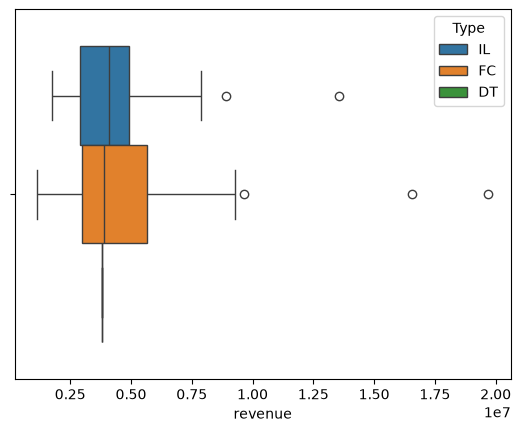

In [12]:
sns.boxplot(data=df, x='revenue', hue='Type')

Тип ресторанов `DT` стоит объединить с наибольшим (`FC`), так случай единичный и может привести к заучиванию результата.

Также еще существует тип `MB`, упомянутый в `reamde`, но в `train.csv` его нет, что видно по графику.

In [13]:
df.loc[df['Type'] == 'DT', 'Type'] = 'FC'

In [14]:
df['Type'].value_counts()

Type
FC    77
IL    60
Name: count, dtype: int64

---
Также надо преобразовать колонку `Open Date`, потому что нейронка не понимает такой формат. Создаем новые колонки с годом и месяцом (день не добавляем, так как это является лишними данными для нашей задачи).

In [15]:
df['Open Date'] = pd.to_datetime(df['Open Date'], format='%m/%d/%Y')

In [16]:
df['Open_Year'] = df['Open Date'].dt.year

In [17]:
df['Open_Month'] = df['Open Date'].dt.month

In [18]:
df = df.drop('Open Date', axis=1)

---
Построим график `scatterplot` по полученной колонке `Open_Year` и целевой переменной `revenue`.

<Axes: xlabel='Open_Year', ylabel='revenue'>

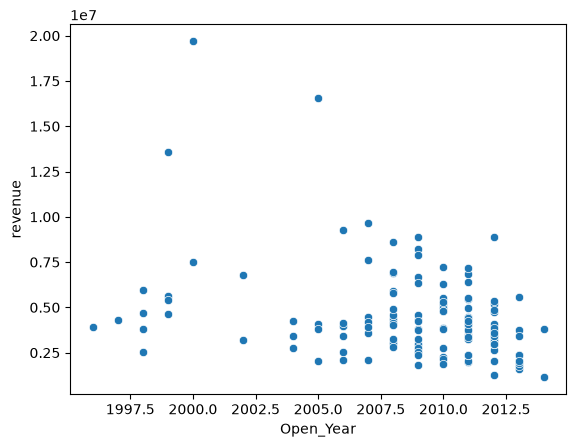

In [19]:
sns.scatterplot(data=df, x = df['Open_Year'], y = df['revenue'])

Как видно на графике, большинство значений кучкуется, но есть и экстремальные, которые скорее всего являются очень успешными ресторанами.

---
Построим еще гистограмму с включенным `kde`.

<Axes: xlabel='revenue', ylabel='Count'>

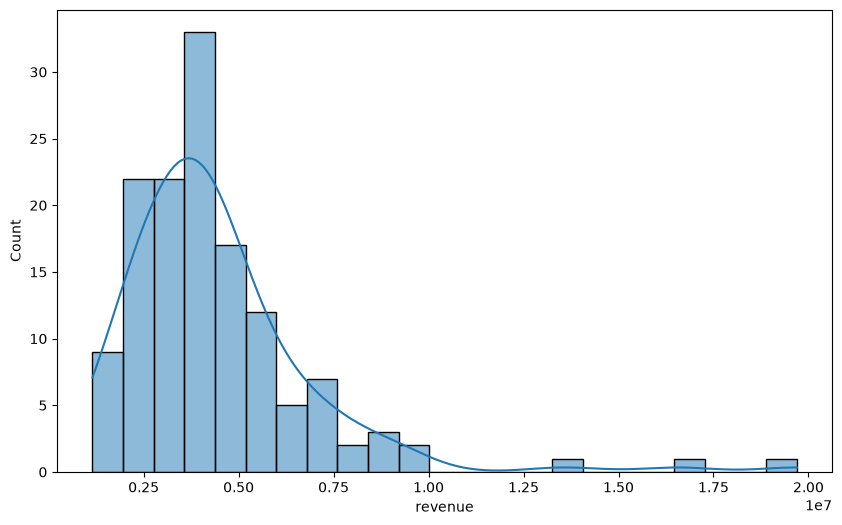

In [20]:
plt.figure(figsize=(10, 6), dpi=100)
sns.histplot(data=df, x='revenue', kde=True)

На графике видно:
- **правосторонняя ассиметрия**: основная масса значений смещена влево,
  но есть длинный хвост вправо;
-  в правой части наблюдаются выбросы
- значения различаются на порядки, что при MSE-лоссе приводит
  к нестабильным градиентам и доминированию крупных наблюдений.


Также построим `boxplot` для понимая, как много выбросов при межквартильного размаха (тоже по годам)

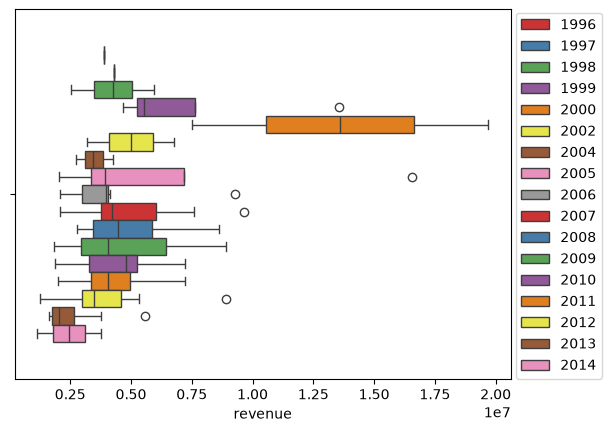

In [21]:
sns.boxplot(data=df, x='revenue', hue='Open_Year', palette='Set1')
plt.legend(loc=(1.01, 0.001))

Как видно, есть выбросы, стоит их удалить. Для начала выведим топ 10 по выручке среди годов, где присутствуют выбросы

In [22]:
df.loc[df['Open_Year'].isin([1999, 2005, 2006, 2007, 2012, 2013])].nlargest(10, 'revenue')['revenue']

75     16549064.0
99     13575224.0
100     9652350.0
133     9262754.0
116     8894598.0
127     7592272.0
0       5653753.0
53      5595267.0
27      5435276.0
18      5337526.0
Name: revenue, dtype: float64

Для стабилизации процесса обучения сети был применим метод межквартильного размаха (IQR). Все наблюдения с `revenue` выше границы Q3 + 1.5 * IQR будут удалены. Это позволит убрать экстремальные аномалии, сохранив при этом большую часть исходного датасета.
Стоит отметить, что эти экстремальные значения, возможно, пригодятся при дальнейшем обучении на `test.csv`, однако в нашу лабораторную работу это не входит (мы и не сможем проверить качество модели, так как там нет таргетов). С этой точки зрения такие значения можно считать выбросами.

In [23]:
Q1 = df['revenue'].quantile(0.25)
Q3 = df['revenue'].quantile(0.75)
upper_bound = Q3 + 1.5 * (Q3 - Q1)

outlier_indices = df.index[df['revenue'] > upper_bound]

df = df.drop(index=outlier_indices).reset_index(drop=True)

---

Посмотрим распределение целевой переменной на гистограмме после удаления выбросов.

<Axes: xlabel='revenue', ylabel='Count'>

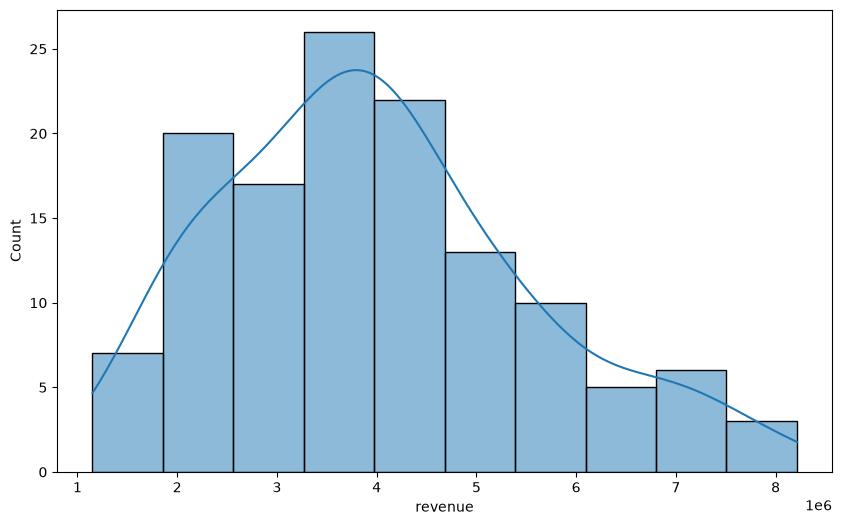

In [24]:
plt.figure(figsize=(10, 6), dpi=100)
sns.histplot(data=df, x='revenue', kde=True)

Видно, что kde сместилость правее и стал больше похож на график нормального распределения (То есть присутсвует симметричная колоколообразная форма).

<Axes: xlabel='revenue'>

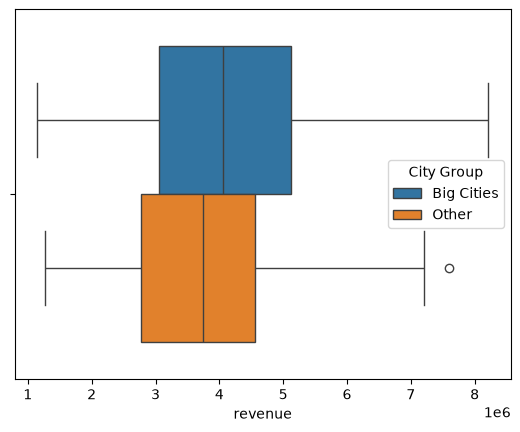

In [25]:
sns.boxplot(data=df, x = 'revenue', hue='City Group')

На данном графике видно, что выручка у больших городов в среднем выше, чем у других (что является логичным). Также как и на гистограмме, видно, что притсутствиуют единичный выброс у обоих групп городов.

---
Удалим колонки `Id` и `City`.

In [26]:
df = df.drop(['Id', 'City'], axis=1)
#df = df.drop('Id', axis=1)

In [27]:
df.head()

,City Group,Type,P1,P2,P3,P4,P5,P6,P7,P8,...,P31,P32,P33,P34,P35,P36,P37,revenue,Open_Year,Open_Month
0,Big Cities,IL,4,5.0,4.0,4.0,2,2,5,4,...,3,4,5,5,4,3,4,5653753.0,1999,7
1,Big Cities,FC,4,5.0,4.0,4.0,1,2,5,5,...,0,0,0,0,0,0,0,6923131.0,2008,2
2,Other,IL,2,4.0,2.0,5.0,2,3,5,5,...,0,0,0,0,0,0,0,2055379.0,2013,3
3,Other,IL,6,4.5,6.0,6.0,4,4,10,8,...,12,10,6,18,12,12,6,2675511.0,2012,2
4,Other,IL,3,4.0,3.0,4.0,2,2,5,5,...,1,3,2,3,4,3,3,4316715.0,2009,5


### Вывод
- Пропусков и дубликатов нет.
- `City` — 34 уникальных значения на 137 строк. То есть кодировать нет смысла (`One-hot Encoding` приведет к огромному кол-ву разреженных колонок, а `LabelEncoder` к заучиванию городов, что приведет к переобучению, поэтому легче удалить колонку и оставить колонки `City Group` и `Type`, а после закодировать по One-hot Encoding)
- `Type`: FC (76), IL (60), DT (1) → DT объединяем с FC (единичное наблюдение). Также в readme есть тип MB, но в `train.csv` его нет.
- Удаляем колонку `Id`, так как бесполезная. Также `City` (причина описана выше)
- Преобразовали колонку `Open Date` в отдельные колонки год (`Open_Year`) и месяц (`Open_Month`), так как нейронка не воспринимает такой формат. Потом удалили колонку `Open Date`.
- Удалили выбросы в целевой переменной, что привело к смещение вправо графика распределения данных. 

---

## Кодирование признаков

In [28]:
df = pd.get_dummies(data=df, columns=['City Group', 'Type'], drop_first=True, dtype=int)

In [29]:
df.head()

,P1,P2,P3,P4,P5,P6,P7,P8,P9,P10,...,P33,P34,P35,P36,P37,revenue,Open_Year,Open_Month,City Group_Other,Type_IL
0,4,5.0,4.0,4.0,2,2,5,4,5,5,...,5,5,4,3,4,5653753.0,1999,7,0,1
1,4,5.0,4.0,4.0,1,2,5,5,5,5,...,0,0,0,0,0,6923131.0,2008,2,0,0
2,2,4.0,2.0,5.0,2,3,5,5,5,5,...,0,0,0,0,0,2055379.0,2013,3,1,1
3,6,4.5,6.0,6.0,4,4,10,8,10,10,...,6,18,12,12,6,2675511.0,2012,2,1,1
4,3,4.0,3.0,4.0,2,2,5,5,5,5,...,2,3,4,3,3,4316715.0,2009,5,1,1


---
Построим тепловую карту и удалим корреллирующие признаки со значениями > 0.9

<Axes: >

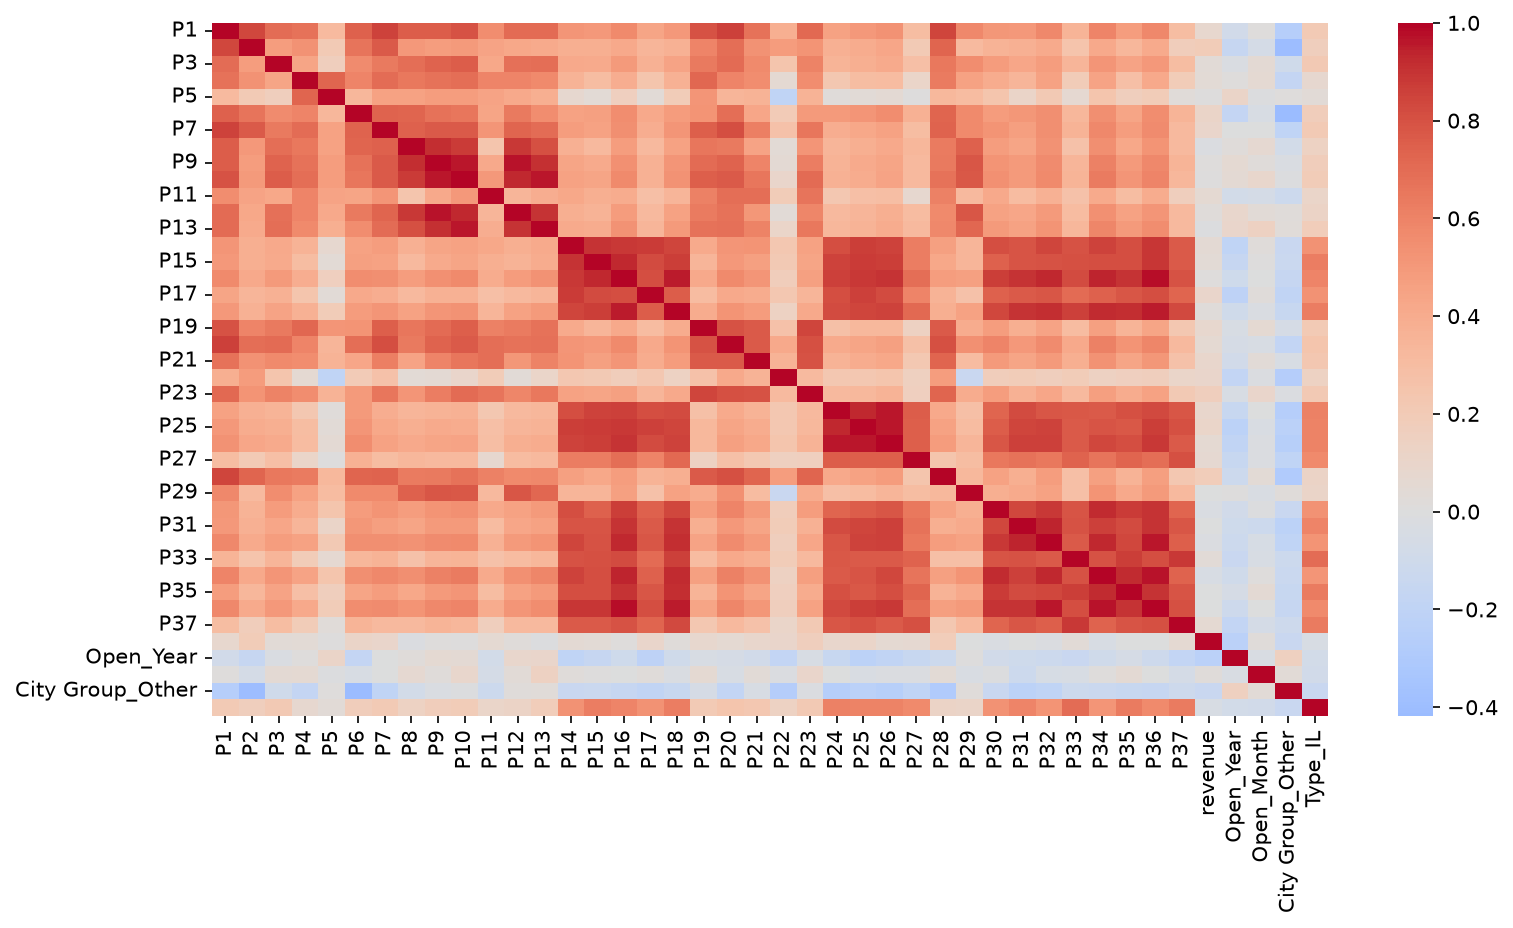

In [30]:
plt.figure(figsize=(12, 6), dpi=150)
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', center=0)

In [31]:
corr_matrix = df.corr(numeric_only=True).abs()

corr_threshold = 0.9
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_tri.columns if upper_tri[col].abs().max() > corr_threshold]

print("Удаляем сильно коррелирующие колонки:", to_drop)

df = df.drop(columns=to_drop)

Удаляем сильно коррелирующие колонки: ['P9', 'P10', 'P12', 'P13', 'P16', 'P18', 'P25', 'P26', 'P32', 'P34', 'P35', 'P36']


* Между некоторыми признаками (`P1` - `P37`) наблюдается сильная линейная взаимосвязь.
* Из пар признаков, коэффициент корреляции между которыми строго превышает **0.9**, один признак удаляется. Это позволяет избежать проблемы мультиколлинеарности, уменьшает размерность пространства признаков, предотвращает переобучение нейронной сети и снижает вычислительную сложность. Всего удалено 12 избыточных колонок.


---
## Масштабирование признаков и разбиение на `train` и `test`

In [32]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

Запишем в отдельные переменные `X` и `y`, то есть на данные без целевой переменной `revenue` и отдельно целевую переменную соответственно.

In [33]:
X = df.drop('revenue', axis=1)

In [34]:
y = df['revenue']

Воспользуемся `train_test_split` и разделим данные в пропорции 80 на 20 (80 - train, 20 - test). Также зададим параметр `random_state` для повторяемости результата, параметр задан субъективно.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

**Почему выбрано деление на $10^6$, а не логарифм (np.log1p)?**

Для подготовки выручки (`revenue`) к обучению нейросети мы просто поделили её на 1 миллион ($10^6$), вместо того чтобы брать логарифм (`np.log1p`). 

**Причины:**

1. **Понятные ошибки (в реальных деньгах):** Когда мы делим на миллион, нейросеть учится считать в миллионах. Если итоговая ошибка MAE получилась `1.4` — это сразу означает ошибку в `1.4 млн`. Если бы мы взяли логарифм, то ошибка считалась бы в логарифмах, и её было бы невозможно нормально оценить.
   
2. **Экспонента повышает ошибку:** Если обучать модель на логарифмах, то для перевода предсказаний обратно в деньги нужно использовать экспоненту (`np.expm1`). На больших числах (миллионах) экспонента работает как увеличительное стекло: если нейросеть ошибется в логарифме всего на «чуть-чуть» (например, на 0.1), то после экспоненты эта микро-ошибка превратится в огромную погрешность в миллионы рублей.

3. **Логарифм не нужен:** Логарифм обычно берут, чтобы «сжать» огромные выбросы или если в данных есть нули. Но нулей у нас нет (минимальная выручка больше 1 млн), а все сильные выбросы мы уже удалили до этого по методу `IQR`. Поэтому обычного деления на миллион абсолютно достаточно, чтобы нейросеть обучалась стабильно.


In [36]:
y_train_mln = y_train / 1e6
y_test_mln  = y_test  / 1e6

Применим `StandardScaler` (стандартизацию), так как она более устойчива к большим значениям (еще используется среднее значени и стандатное отклонение всей выборки, значит, основная масса будет распределена вокруг нуля), чем тот же `MinMaxScaler`. Параметры масштабирования (`fit`) рассчитываются исключительно по обучающей выборке, после чего применяются к обучающему и тестовому наборам для предотвращения утечки данных

In [37]:
scaler = StandardScaler()

In [38]:
scaled_X_train = scaler.fit_transform(X_train)

In [39]:
scaled_X_test = scaler.transform(X_test)

Text(0.5, 1.0, 'Boxplot признаков до масштабирования (train)')

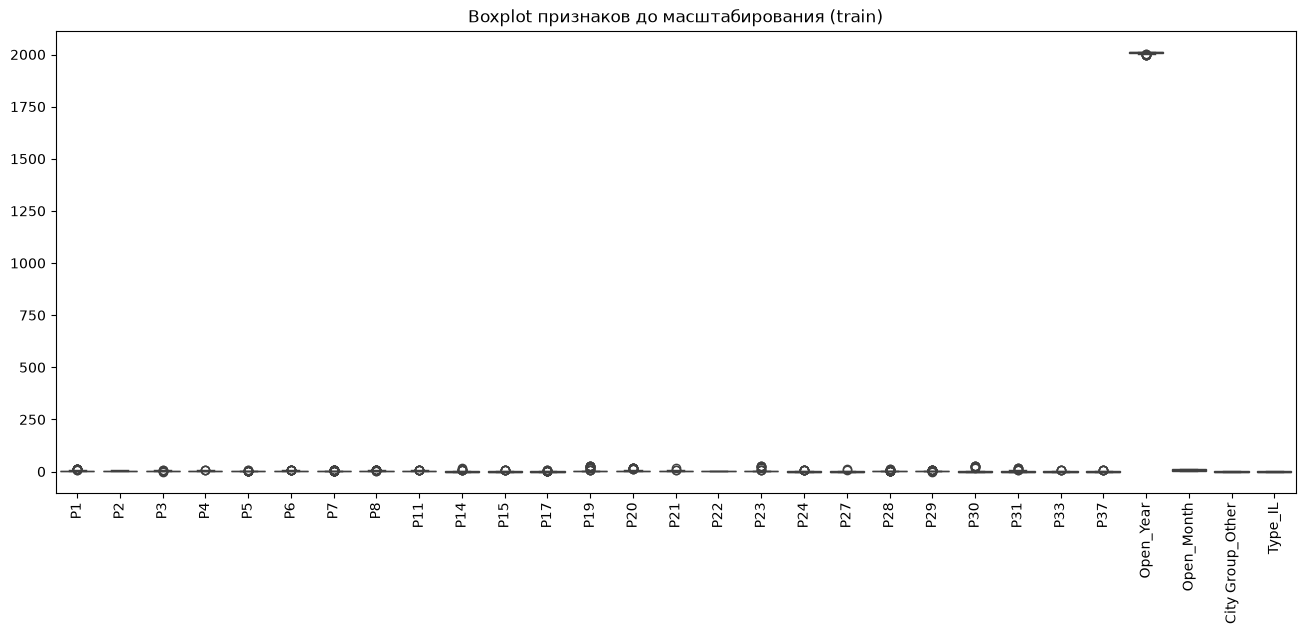

In [40]:
plt.figure(figsize=(16, 6), dpi=100)
sns.boxplot(data=X_train)
plt.xticks(rotation=90)
plt.title('Boxplot признаков до масштабирования (train)')

Text(0.5, 1.0, 'Boxplot признаков после масшатибрования (train)')

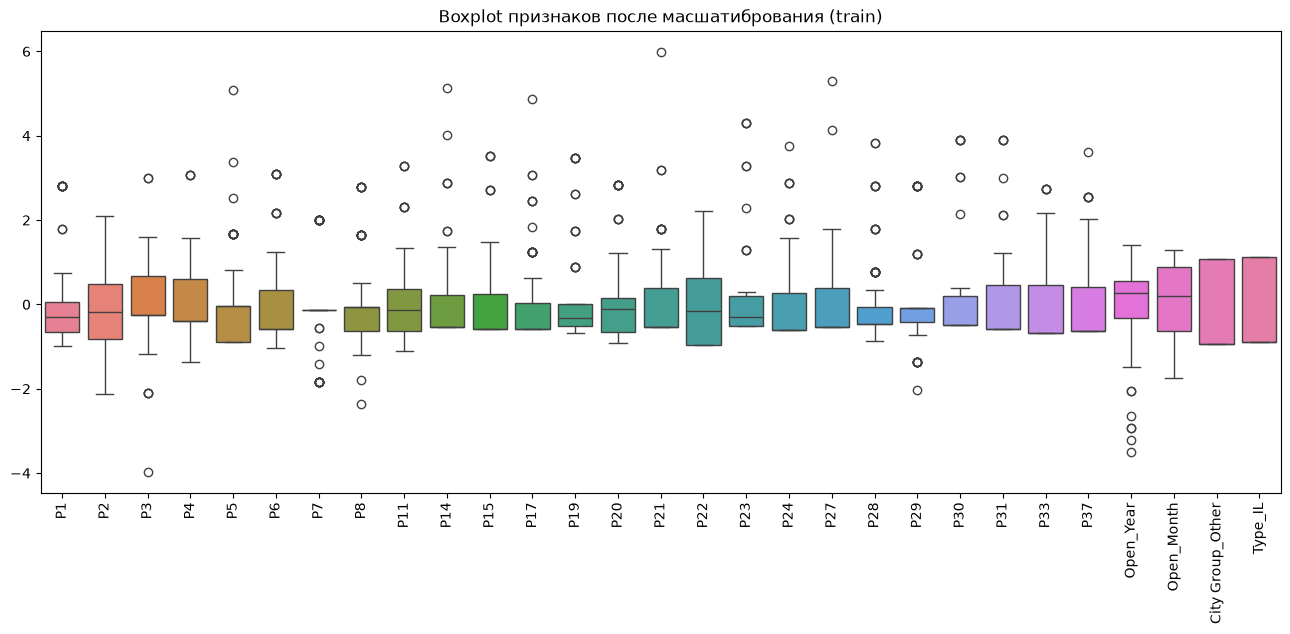

In [41]:
scaled_train_df = pd.DataFrame(scaled_X_train, columns=X_train.columns)

plt.figure(figsize=(16, 6), dpi=100)
sns.boxplot(data=scaled_train_df)
plt.xticks(rotation=90)
plt.title('Boxplot признаков после масшатибрования (train)')

Text(0.5, 1.0, 'Boxplot признаков до масштабирования (test)')

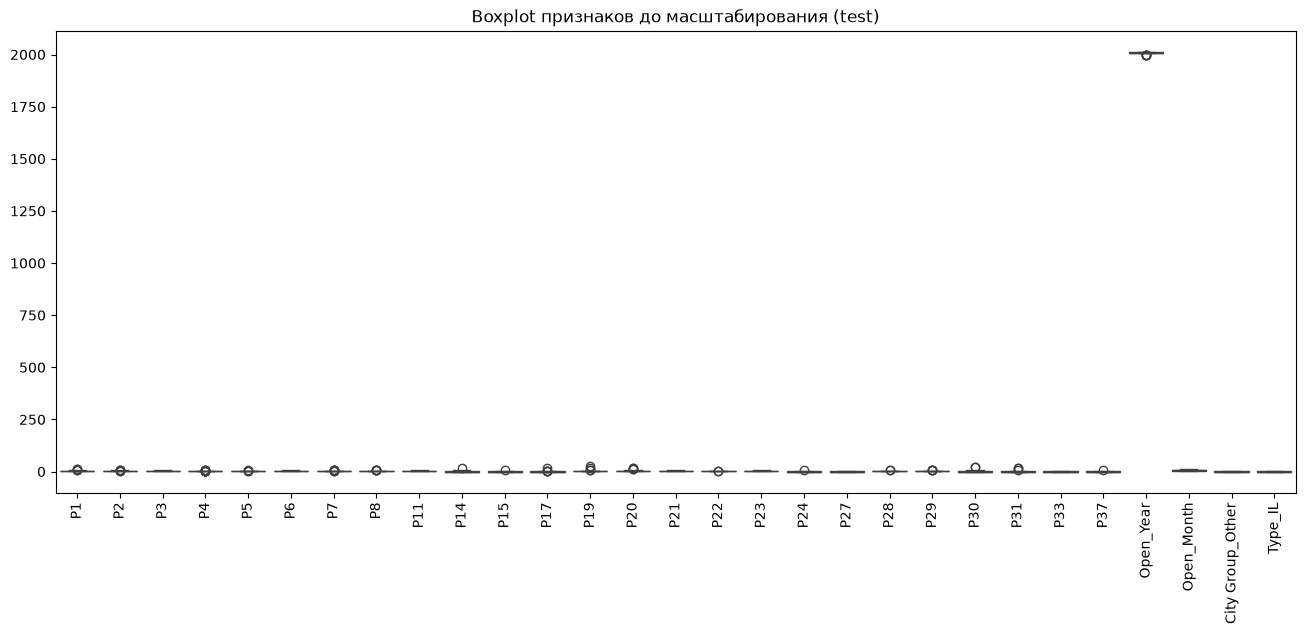

In [42]:
plt.figure(figsize=(16, 6), dpi=100)
sns.boxplot(data=X_test)
plt.xticks(rotation=90)
plt.title('Boxplot признаков до масштабирования (test)')

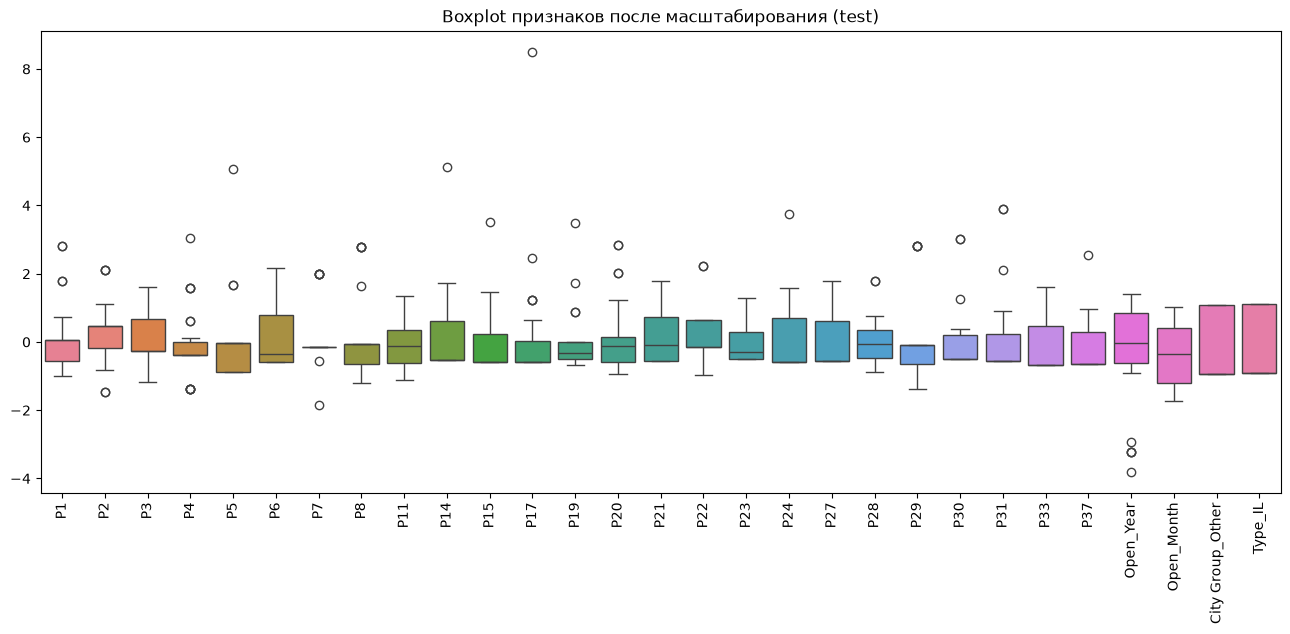

In [43]:
scaled_test_df = pd.DataFrame(scaled_X_test, columns=X_test.columns)

plt.figure(figsize=(16, 6), dpi=100)
sns.boxplot(data=scaled_test_df)
plt.xticks(rotation=90)
plt.title('Boxplot признаков после масштабирования (test)')
plt.show()


После стандартизации признаки имеют нулевое среднее и единичный
дисперсия: боксы сгруппированы вокруг нуля. One-hot признаки имеют
два возможных значения, что объясняет их характерный вид на боксплотах.

---
## Построение полносвязной модели на keras

In [44]:
import keras
from keras import layers
keras.utils.set_random_seed(101)

Зафиксируем `seed`, чтобы не было постоянной случайности в весах нейронки и в работе Dropout

**Архитектура и обучение нейронной сети**

Архитектура нейронной сети, а также интенсивность слоев регуляризации (`Dropout` со значениями 0.4 и 0.3) были подобраны **эмпирическим путем (в ходе экспериментов)**. 

**Обоснование настройки:**
* Исходная модель без регуляризации демонстрировала признаки переобучения (разрыв между ошибкой на обучающей и валидационной выборках рос с увеличением эпох).
* Для борьбы с оверфиттингом были последовательно протестированы различные коэффициенты Dropout. Итоговые значения (0.4 для первого и второго) были выбраны как оптимальные, так как они позволили удержать метрики `loss` и `val_loss` на близком уровне и обеспечили наилучшую обобщающую способность модели на тестовых данных.
* В качестве оптимизатора используется `Adam` с `lr` равным  0.001, функция потерь `mse`. Метрики выбраны как указано в задании к лабораторной работе, а именно `mae` и `rmse`.

In [45]:
model = keras.Sequential(
    [
        layers.Input(shape=(scaled_X_train.shape[1], )),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(1),
    ]
)

In [46]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), 
              loss='mean_squared_error', 
              metrics=['mean_absolute_error',
              keras.metrics.RootMeanSquaredError(name='root_mean_squared_error')])

In [47]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,505 (5.88 KB)

 Trainable params: 1,505 (5.88 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
history = model.fit(scaled_X_train, y_train_mln, epochs=100, batch_size=32, validation_split=0.2) 

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 269ms/step - loss: 22.3623 - mean_absolute_error: 4.4116 - root_mean_squared_error: 4.7289 - val_loss: 23.7765 - val_mean_absolute_error: 4.5240 - val_root_mean_squared_error: 4.8761
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 21.3528 - mean_absolute_error: 4.1951 - root_mean_squared_error: 4.6209 - val_loss: 22.4234 - val_mean_absolute_error: 4.3785 - val_root_mean_squared_error: 4.7353
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 20.1076 - mean_absolute_error: 4.0852 - root_mean_squared_error: 4.4841 - val_loss: 21.1475 - val_mean_absolute_error: 4.2353 - val_root_mean_squared_error: 4.5986
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 19.8245 - mean_absolute_error: 4.0457 - root_mean_squared_error: 4.4525 - val_loss: 19.9524 - val_mean_absolute_error: 4.0946 - val_root_mean_squared_error: 4.4668
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 20.6495 - mean_absolute_error: 4.1190 - root_mean_squ

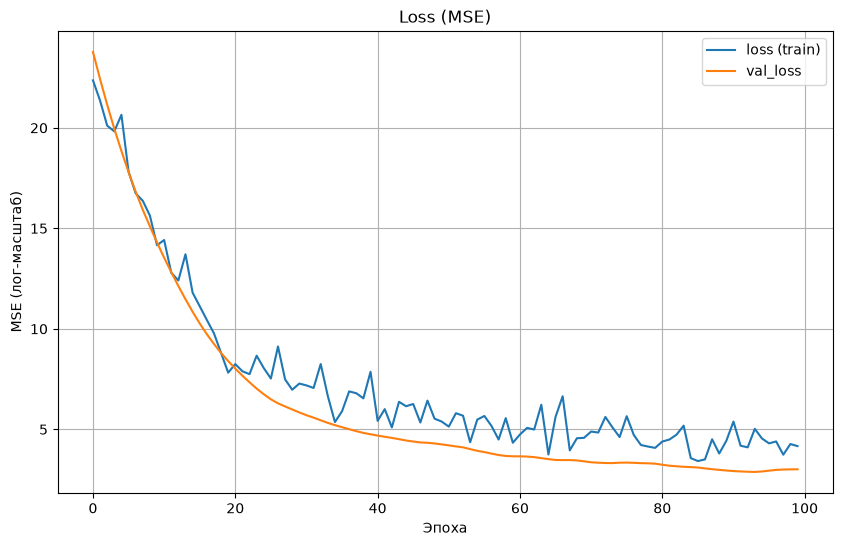

In [49]:
plt.figure(figsize=(10, 6), dpi=100)

plt.plot(history.history['loss'], label='loss (train)')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Эпоха')
plt.ylabel('MSE (лог-масштаб)')
plt.title('Loss (MSE)')
plt.legend()
plt.grid()

* На графиках функций потерь, `mae` и `rmse` (`train` и `val`) видно плавное валидационной выборки, но у обучающей присутсвует рваность из-за маленького датасета и слоев регуляризации (`Dropout`). То есть при другом разбиение данных результат может отличаться от нынешного, также стоит учитывать, что изначальные веса для нейронной сети подбираются случайно.
* Валидационная выборка не начинает расти вверх к концу обучения, а идет параллельно тренировочному, что свидетельствует об отсутствии переобучения (`overfitting`) модели благодаря правильно подобранным слоям Dropout.


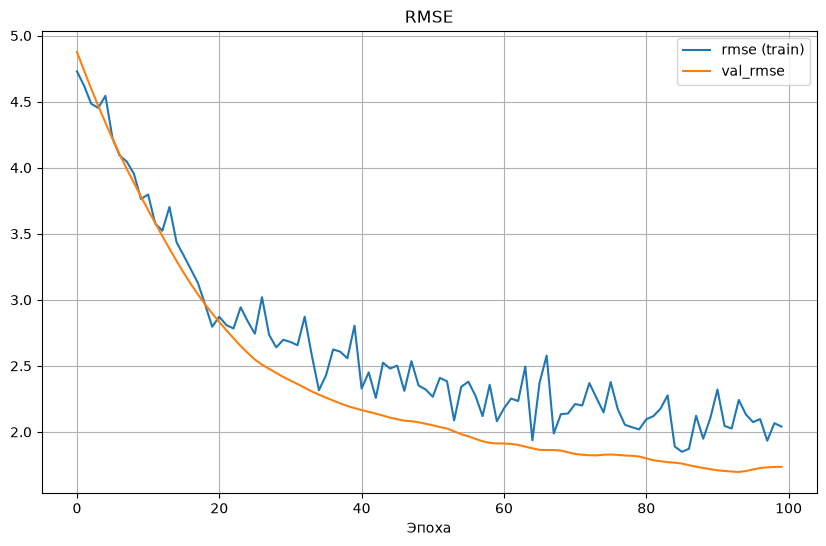

In [50]:
plt.figure(figsize=(10, 6), dpi=100)

plt.plot(history.history['root_mean_squared_error'], label='rmse (train)')
plt.plot(history.history['val_root_mean_squared_error'], label='val_rmse')
plt.xlabel('Эпоха')
plt.title('RMSE')
plt.legend(); 
plt.grid()


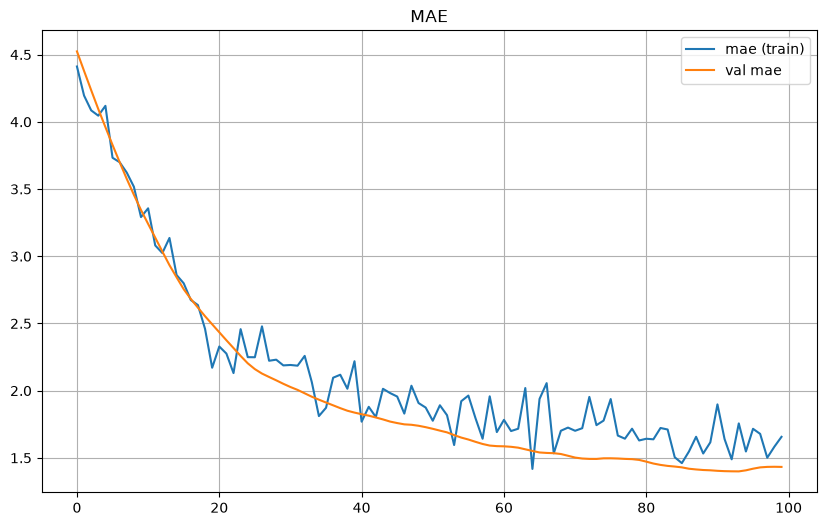

In [51]:
plt.figure(figsize=(10,6), dpi=100)

plt.plot(history.history['mean_absolute_error'], label='mae (train)')
plt.plot(history.history['val_mean_absolute_error'], label='val mae')
plt.title('MAE')
plt.legend()
plt.grid()

---
Теперь сделаем прогноз на тестовом наборе (стандартизированном). 

In [52]:
y_pred = model.predict(scaled_X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

Возвращаем предсказания в реальные значения (то есть убираем деление на `1e6`), используем `.flatten()`,так как модель выдает предсказание в двумернном массиве размером `[N, 1]`, а нам нужен одномерный массив. Тестовой выборки не касается, так как ее мы не преобразовывали.

In [54]:
y_pred_real = y_pred.flatten() * 1e6

final_mae = mean_absolute_error(y_test, y_pred_real)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_real))

print(f"Итоговый MAE: {final_mae:,.2f}")
print(f"Итоговый: {final_rmse:,.2f}")


Итоговый MAE: 1,283,608.31
Итоговый: 1,758,318.98


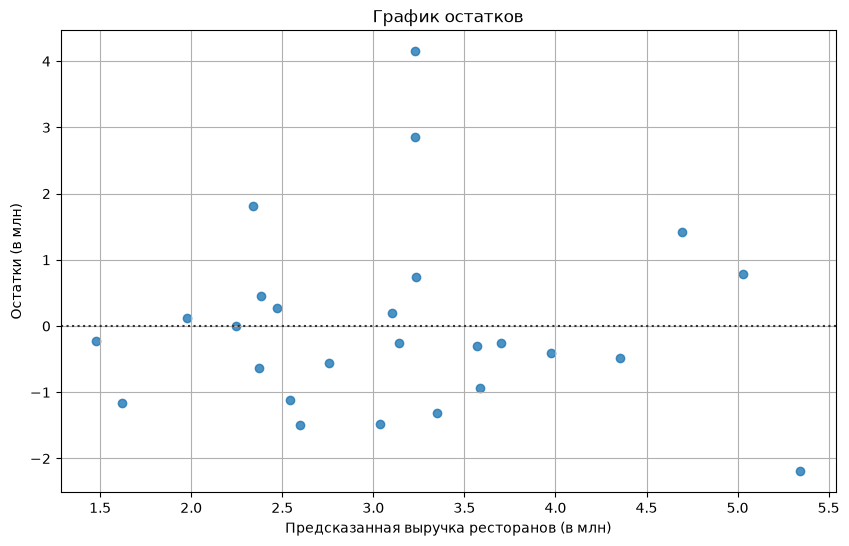

In [55]:
y_test_mln = y_test / 1e6
y_pred_real_mln = y_pred_real / 1e6

plt.figure(figsize=(10, 6), dpi=100)
sns.residplot(x=y_pred_real_mln, y=y_test_mln)

plt.xlabel('Предсказанная выручка ресторанов (в млн)')
plt.ylabel('Остатки (в млн)')
plt.title('График остатков')
plt.grid()


## Оценка качества модели на тестовых данных

**Итоговые метрики на тестовой выборке:**
* **MAE (Средняя абсолютная ошибка):** ~1.3 млн. В среднем модель ошибается в прогнозе годовой выручки ресторана примерно на 1.3 млн.
* **RMSE (Корень из среднеквадратичной ошибки):** ~1.77 млн. 

**Анализ графика остатков (Residual Plot)**
График остатков показывает распределение ошибок предсказания (`y_true - y_pred`) относительно предсказанных значений:
* Точки распределены относительно горизонтальной оси `y=0` достаточно хаотично, явных нелинейных паттернов (U-образных форм, квартета Энскомбо) не наблюдается, что говорит о том, что сеть успешно извлекла основные зависимости.


## Заключение

В ходе лабораторной работы были освоены навыки предобработки табличных данных и построения полносвязной нейронной сети в Keras для решения задачи регрессии. Однако по итогам анализа результатов можно сделать вывод, что полносвязная нейронная сеть **не является оптимальным выбором** для данной задачи.

### Причины неэффективности нейросети:
* **Критически малый объем данных(С точки зрения `train.csv`):** Нейросети имеют тысячи настраиваемых параметров и требуют огромных датасетов, а на малых выборках они работают нестабильно.
* **Природа данных:** Для структурированных таблиц малого и среднего объема классические алгоритмы машинного обучения всегда работают точнее и быстрее нейросетей.

Вместо глубокого обучения для прогнозирования выручки **эффективнее** использовать классическое машинное обучение

